## Project Description: Next Word Prediction Using LSTM
#### Project Overview:

This project aims to develop a deep learning model for predicting the next word in a given sequence of words. The model is built using Long Short-Term Memory (LSTM) networks, which are well-suited for sequence prediction tasks. The project includes the following steps:

1- Data Collection: We use the text of Shakespeare's "Hamlet" as our dataset. This rich, complex text provides a good challenge for our model.

2- Data Preprocessing: The text data is tokenized, converted into sequences, and padded to ensure uniform input lengths. The sequences are then split into training and testing sets.

3- Model Building: An LSTM model is constructed with an embedding layer, two LSTM layers, and a dense output layer with a softmax activation function to predict the probability of the next word.

4- Model Training: The model is trained using the prepared sequences, with early stopping implemented to prevent overfitting. Early stopping monitors the validation loss and stops training when the loss stops improving.

5- Model Evaluation: The model is evaluated using a set of example sentences to test its ability to predict the next word accurately.

6- Deployment: A Streamlit web application is developed to allow users to input a sequence of words and get the predicted next word in real-time.

In [1]:
import tensorflow as tf
import time
import sys

print("GPU:", tf.config.list_physical_devices('GPU'))
print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)



GPU: []
Python: d:\Me\DataScience\JupyterFile_ML\DeepLearning\v310\Scripts\python.exe
TensorFlow: 2.15.0


In [3]:
## Data Collection
import nltk
nltk.download('gutenberg')
from nltk.corpus import gutenberg
import  pandas as pd

## load the dataset
data=gutenberg.raw('shakespeare-hamlet.txt')
## save to a file
with open('hamlet.txt','w') as file:
    file.write(data)


[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\vivek\AppData\Roaming\nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!


In [4]:
## Data Preprocessing

import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

##laod the dataset
with open('hamlet.txt','r') as file:
    text=file.read().lower()

## Tokenize the text-creating indexes for words
tokenizer=Tokenizer()
tokenizer.fit_on_texts([text])
total_words=len(tokenizer.word_index)+1
total_words



4818

In [5]:
tokenizer.word_index
# text

{'the': 1,
 'and': 2,
 'to': 3,
 'of': 4,
 'i': 5,
 'you': 6,
 'a': 7,
 'my': 8,
 'it': 9,
 'in': 10,
 'that': 11,
 'ham': 12,
 'is': 13,
 'not': 14,
 'his': 15,
 'this': 16,
 'with': 17,
 'your': 18,
 'but': 19,
 'for': 20,
 'me': 21,
 'lord': 22,
 'as': 23,
 'what': 24,
 'he': 25,
 'be': 26,
 'so': 27,
 'him': 28,
 'haue': 29,
 'king': 30,
 'will': 31,
 'no': 32,
 'our': 33,
 'we': 34,
 'on': 35,
 'are': 36,
 'if': 37,
 'all': 38,
 'then': 39,
 'shall': 40,
 'by': 41,
 'thou': 42,
 'come': 43,
 'or': 44,
 'hamlet': 45,
 'good': 46,
 'do': 47,
 'hor': 48,
 'her': 49,
 'let': 50,
 'now': 51,
 'thy': 52,
 'how': 53,
 'more': 54,
 'they': 55,
 'from': 56,
 'enter': 57,
 'at': 58,
 'was': 59,
 'oh': 60,
 'like': 61,
 'most': 62,
 'there': 63,
 'well': 64,
 'know': 65,
 'selfe': 66,
 'would': 67,
 'them': 68,
 'loue': 69,
 'may': 70,
 "'tis": 71,
 'vs': 72,
 'sir': 73,
 'qu': 74,
 'which': 75,
 'did': 76,
 'why': 77,
 'laer': 78,
 'giue': 79,
 'thee': 80,
 'ile': 81,
 'must': 82,
 'hath': 

In [6]:
## create inoput sequences
input_sequences=[]
for line in text.split('\n'):
    token_list=tokenizer.texts_to_sequences([line])[0]
    for i in range(1,len(token_list)):
        n_gram_sequence=token_list[:i+1]
        input_sequences.append(n_gram_sequence)

        

In [7]:
input_sequences
# len(input_sequences)

[[1, 687],
 [1, 687, 4],
 [1, 687, 4, 45],
 [1, 687, 4, 45, 41],
 [1, 687, 4, 45, 41, 1886],
 [1, 687, 4, 45, 41, 1886, 1887],
 [1, 687, 4, 45, 41, 1886, 1887, 1888],
 [1180, 1889],
 [1180, 1889, 1890],
 [1180, 1889, 1890, 1891],
 [57, 407],
 [57, 407, 2],
 [57, 407, 2, 1181],
 [57, 407, 2, 1181, 177],
 [57, 407, 2, 1181, 177, 1892],
 [407, 1182],
 [407, 1182, 63],
 [408, 162],
 [408, 162, 377],
 [408, 162, 377, 21],
 [408, 162, 377, 21, 247],
 [408, 162, 377, 21, 247, 882],
 [18, 66],
 [451, 224],
 [451, 224, 248],
 [451, 224, 248, 1],
 [451, 224, 248, 1, 30],
 [408, 407],
 [451, 25],
 [408, 6],
 [408, 6, 43],
 [408, 6, 43, 62],
 [408, 6, 43, 62, 1893],
 [408, 6, 43, 62, 1893, 96],
 [408, 6, 43, 62, 1893, 96, 18],
 [408, 6, 43, 62, 1893, 96, 18, 566],
 [451, 71],
 [451, 71, 51],
 [451, 71, 51, 1894],
 [451, 71, 51, 1894, 567],
 [451, 71, 51, 1894, 567, 378],
 [451, 71, 51, 1894, 567, 378, 80],
 [451, 71, 51, 1894, 567, 378, 80, 3],
 [451, 71, 51, 1894, 567, 378, 80, 3, 273],
 [451, 71

In [8]:
## Pad Sequences
max_sequence_len=max([len(x) for x in input_sequences])
max_sequence_len

14

In [9]:
input_sequences=np.array(pad_sequences(input_sequences,maxlen=max_sequence_len,padding='pre'))
input_sequences

array([[   0,    0,    0, ...,    0,    1,  687],
       [   0,    0,    0, ...,    1,  687,    4],
       [   0,    0,    0, ...,  687,    4,   45],
       ...,
       [   0,    0,    0, ...,    4,   45, 1047],
       [   0,    0,    0, ...,   45, 1047,    4],
       [   0,    0,    0, ..., 1047,    4,  193]])

In [10]:
##create predicitors and label
import tensorflow as tf
x,y=input_sequences[:,:-1],input_sequences[:,-1]

In [11]:
x


array([[   0,    0,    0, ...,    0,    0,    1],
       [   0,    0,    0, ...,    0,    1,  687],
       [   0,    0,    0, ...,    1,  687,    4],
       ...,
       [   0,    0,    0, ...,  687,    4,   45],
       [   0,    0,    0, ...,    4,   45, 1047],
       [   0,    0,    0, ...,   45, 1047,    4]])

In [12]:
y

array([ 687,    4,   45, ..., 1047,    4,  193])

In [13]:
y=tf.keras.utils.to_categorical(y,num_classes=total_words)
y

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

## Train / Validation / Test Split

The validation set is used for hyperparameter tuning. The test set is kept untouched until the final evaluation.

In [14]:
# Split into train (80%), validation (10%), and test (10%)
# First separate 20% into a temporary set, then split that equally.
x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.20, random_state=42
)

x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.50, random_state=42
)

print("Train:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)


Train: (20585, 13) (20585, 4818)
Validation: (2573, 13) (2573, 4818)
Test: (2574, 13) (2574, 4818)


## Early Stopping

Use a short patience during tuning to avoid wasting time on weak trials.

In [15]:
from tensorflow.keras.callbacks import EarlyStopping

tuner_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

final_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)


## LSTM Hyperparameter Search

KerasTuner Random Search will choose the embedding size, both LSTM sizes, dropout, recurrent dropout, and learning rate. The objective is minimum validation loss.

In [16]:
import keras_tuner as kt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.optimizers import Adam

def build_model(hp):
    model = Sequential()

    model.add(
        Embedding(
            input_dim=total_words,
            output_dim=hp.Choice("embedding_dim", [64, 100, 128]),
            input_length=max_sequence_len - 1
        )
    )

    model.add(
        LSTM(
            units=hp.Choice("lstm1_units", [64, 128, 150]),
            return_sequences=True,
            dropout=hp.Choice("dropout1", [0.0, 0.1, 0.2, 0.3]),
            recurrent_dropout=hp.Choice(
                "recurrent_dropout1", [0.0, 0.1, 0.2]
            )
        )
    )

    model.add(
        LSTM(
            units=hp.Choice("lstm2_units", [32, 64, 100]),
            dropout=hp.Choice("dropout2", [0.0, 0.1, 0.2, 0.3]),
            recurrent_dropout=hp.Choice(
                "recurrent_dropout2", [0.0, 0.1, 0.2]
            )
        )
    )

    model.add(Dense(total_words, activation="softmax"))

    learning_rate = hp.Choice(
        "learning_rate", [0.001, 0.0005, 0.0001]
    )

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


In [17]:
tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective=kt.Objective("val_loss", direction="min"),
    max_trials=30,
    directory="tuning",
    project_name="shakespeare_lstm_v2",
    overwrite=True
)

tuner.search_space_summary()



Search space summary
Default search space size: 8
embedding_dim (Choice)
{'default': 64, 'conditions': [], 'values': [64, 100, 128], 'ordered': True}
lstm1_units (Choice)
{'default': 64, 'conditions': [], 'values': [64, 128, 150], 'ordered': True}
dropout1 (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.1, 0.2, 0.3], 'ordered': True}
recurrent_dropout1 (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.1, 0.2], 'ordered': True}
lstm2_units (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64, 100], 'ordered': True}
dropout2 (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.1, 0.2, 0.3], 'ordered': True}
recurrent_dropout2 (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.1, 0.2], 'ordered': True}
learning_rate (Choice)
{'default': 0.001, 'conditions': [], 'values': [0.001, 0.0005, 0.0001], 'ordered': True}


In [18]:
tuner.search(
    x_train,
    y_train,
    epochs=20,
    validation_data=(x_val, y_val),
    callbacks=[tuner_early_stopping],
    verbose=1
)


Trial 30 Complete [00h 01m 14s]
val_loss: 6.70442533493042

Best val_loss So Far: 6.6295342445373535
Total elapsed time: 00h 33m 48s


## Best Hyperparameters

In [19]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

for name, value in best_hp.values.items():
    print(f"{name}: {value}")


embedding_dim: 100
lstm1_units: 150
dropout1: 0.3
recurrent_dropout1: 0.0
lstm2_units: 32
dropout2: 0.1
recurrent_dropout2: 0.2
learning_rate: 0.001


In [20]:
tuner.results_summary(num_trials=10)


Results summary
Results in tuning\shakespeare_lstm_v2
Showing 10 best trials
Objective(name="val_loss", direction="min")

Trial 20 summary
Hyperparameters:
embedding_dim: 100
lstm1_units: 150
dropout1: 0.3
recurrent_dropout1: 0.0
lstm2_units: 32
dropout2: 0.1
recurrent_dropout2: 0.2
learning_rate: 0.001
Score: 6.6295342445373535

Trial 17 summary
Hyperparameters:
embedding_dim: 64
lstm1_units: 128
dropout1: 0.2
recurrent_dropout1: 0.1
lstm2_units: 32
dropout2: 0.3
recurrent_dropout2: 0.2
learning_rate: 0.001
Score: 6.629643440246582

Trial 22 summary
Hyperparameters:
embedding_dim: 128
lstm1_units: 128
dropout1: 0.2
recurrent_dropout1: 0.2
lstm2_units: 64
dropout2: 0.1
recurrent_dropout2: 0.0
learning_rate: 0.0005
Score: 6.643066883087158

Trial 21 summary
Hyperparameters:
embedding_dim: 128
lstm1_units: 128
dropout1: 0.2
recurrent_dropout1: 0.0
lstm2_units: 64
dropout2: 0.0
recurrent_dropout2: 0.2
learning_rate: 0.0005
Score: 6.643770694732666

Trial 12 summary
Hyperparameters:
embedd

## Build and Train the Best LSTM

Important: train `best_model`, not the original manually created `model`.

In [21]:
best_model = tuner.hypermodel.build(best_hp)
best_model.summary()

history = best_model.fit(
    x_train,
    y_train,
    epochs=50,
    validation_data=(x_val, y_val),
    verbose=1,
    callbacks=[final_early_stopping]
)


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_1 (Embedding)     (None, 13, 100)           481800    
                                                                 
 lstm_2 (LSTM)               (None, 13, 150)           150600    
                                                                 
 lstm_3 (LSTM)               (None, 32)                23424     
                                                                 
 dense_1 (Dense)             (None, 4818)              158994    
                                                                 
Total params: 814818 (3.11 MB)
Trainable params: 814818 (3.11 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Epoch 1/50
644/644 [==============================] - 15s 19ms/step - loss: 6.9364 - accuracy: 0.0325 - val_loss: 6.6296 - val_accuracy: 0.0323
Epoch 

## Final Evaluation on the Unseen Test Set

In [22]:
test_loss, test_accuracy = best_model.evaluate(
    x_test, y_test, verbose=1
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")


81/81 [==============================] - 1s 9ms/step - loss: 6.7529 - accuracy: 0.0350
Test loss: 6.7529
Test accuracy: 0.0350


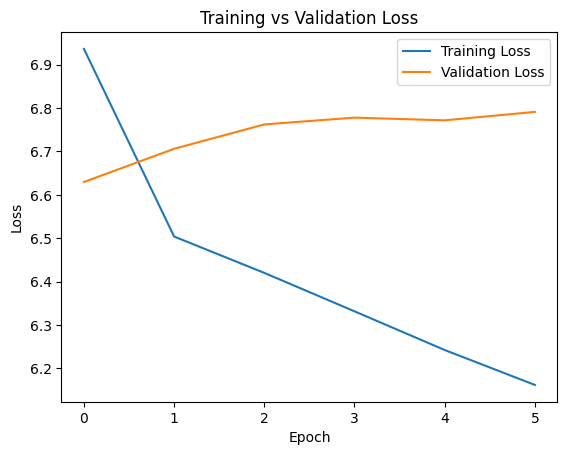

In [23]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()


## Next-Word Prediction

In [24]:
def predict_next_word(model, tokenizer, text, max_sequence_len):
    token_list = tokenizer.texts_to_sequences([text])[0]

    if not token_list:
        return None

    token_list = token_list[-(max_sequence_len - 1):]
    token_list = pad_sequences(
        [token_list],
        maxlen=max_sequence_len - 1,
        padding="pre"
    )

    predicted = model.predict(token_list, verbose=0)
    predicted_word_index = int(np.argmax(predicted, axis=1)[0])

    for word, index in tokenizer.word_index.items():
        if index == predicted_word_index:
            return word

    return None

input_text = "To be or not to be"
next_word = predict_next_word(
    best_model, tokenizer, input_text, max_sequence_len
)

print(f"Input text: {input_text}")
print(f"Next word prediction: {next_word}")


Input text: To be or not to be
Next word prediction: the


## Save the Tuned Model and Tokenizer

In [25]:
best_model.save("next_word_lstm_tuned.h5")

import pickle
with open("tokenizer.pickle", "wb") as handle:
    pickle.dump(
        tokenizer,
        handle,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print("Tuned model and tokenizer saved successfully.")


Tuned model and tokenizer saved successfully.


d:\Me\DataScience\JupyterFile_ML\DeepLearning\v310\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(
